# 04 — Operational interpretation and evidence cards

            This notebook translates the saved evaluation results into a staff-readable evidence format. It is not a live dashboard and it does not claim that historical test metrics are live building alerts. The client-facing use is a concise model-evidence card: what was tested, how reliable the result was on that evaluation, and what qualification is required before deployment.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'normal': '#457b9d', 'fault': '#e76f51', 'accent': '#2a9d8f', 'dark': '#264653'}

def find_root():
    for candidate in [Path.cwd(), Path.cwd().parent, Path('/Users/mili/Desktop/IRPN')]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'results').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the IRPN repository or set ROOT manually.')

ROOT = find_root()

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def require(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing saved artefacts. Run the pipeline commands first:\n' + '\n'.join(missing))

def pct(value):
    return f'{100 * value:.1f}%' if pd.notna(value) else 'n/a'

## 1. Load the final evidence artefacts

In [2]:
BUILDING = ROOT / 'results' / 'building_specific'
QUALITY = ROOT / 'results' / 'quality_controlled' / 'exclude_ambiguous_keys'
AUDIT = ROOT / 'results' / 'audit'
require(BUILDING / 'building_detection_test_metrics.csv', BUILDING / 'building_detection_selected_models.csv', QUALITY / 'quality_detection_metrics_summary.csv', AUDIT / 'audit_manifest.json')
test = pd.read_csv(BUILDING / 'building_detection_test_metrics.csv')
selected = pd.read_csv(BUILDING / 'building_detection_selected_models.csv')
quality_summary = pd.read_csv(QUALITY / 'quality_detection_metrics_summary.csv')
audit_manifest = read_json(AUDIT / 'audit_manifest.json')
display(test.round(3))

,design,fold,rows,normal_support,fault_support,accuracy,balanced_accuracy,precision,recall,f1,...,true_negative,false_positive,false_negative,true_positive,model,building,stage,scored_rows,unscored_rows,coverage
0,building_ahu_held_out,fold_001,26164,14419,11745,0.997,0.997,0.998,0.996,0.997,...,14396,23,44,11701,xgboost,auditorium,test,26164,0,1.0
1,building_chronological,fold_001,22685,12989,9696,1.000,1.000,1.000,1.000,1.000,...,12988,1,1,9695,xgboost,auditorium,test,22685,0,1.0
2,building_ahu_held_out,fold_001,16420,7897,8523,0.489,0.507,0.613,0.041,0.077,...,7676,221,8173,350,xgboost,hospital,test,16420,0,1.0
3,building_chronological,fold_001,13136,10967,2169,0.957,0.958,0.814,0.959,0.880,...,10491,476,89,2080,xgboost,hospital,test,13136,0,1.0
4,building_ahu_held_out,fold_001,35102,23923,11179,0.998,0.997,1.000,0.995,0.997,...,23919,4,59,11120,xgboost,office,test,35102,0,1.0
5,building_chronological,fold_001,35114,26030,9084,0.998,0.997,0.997,0.995,0.996,...,26007,23,47,9037,xgboost,office,test,35114,0,1.0


## 2. Evidence cards for facilities staff

In [3]:
def reliability_label(f1):
    if f1 >= 0.90:
        return 'Strong on this evaluation'
    if f1 >= 0.70:
        return 'Promising; calibrate before use'
    return 'Not reliable for deployment'

cards = test.copy()
cards['evaluation'] = cards['building'] + ' / ' + cards['design'].str.replace('building_', '', regex=False)
cards['evidence_status'] = cards['f1'].map(reliability_label)
cards['staff_message'] = np.where(
    cards['f1'] >= 0.90,
    'Candidate detector for this building and evaluation setting; confirm with target-building calibration.',
    np.where(cards['f1'] >= 0.70, 'Use only as a research aid; collect local normal data and recalibrate.', 'Do not use for operational decisions without redesign and recalibration.')
)
display(cards[['evaluation', 'model', 'evidence_status', 'f1', 'balanced_accuracy', 'false_positive_rate', 'coverage', 'staff_message']].round(3))

,evaluation,model,evidence_status,f1,balanced_accuracy,false_positive_rate,coverage,staff_message
0,auditorium / ahu_held_out,xgboost,Strong on this evaluation,0.997,0.997,0.002,1.0,Candidate detector for this building and evalu...
1,auditorium / chronological,xgboost,Strong on this evaluation,1.000,1.000,0.000,1.0,Candidate detector for this building and evalu...
2,hospital / ahu_held_out,xgboost,Not reliable for deployment,0.077,0.507,0.028,1.0,Do not use for operational decisions without r...
3,hospital / chronological,xgboost,Promising; calibrate before use,0.880,0.958,0.043,1.0,Use only as a research aid; collect local norm...
4,office / ahu_held_out,xgboost,Strong on this evaluation,0.997,0.997,0.000,1.0,Candidate detector for this building and evalu...
5,office / chronological,xgboost,Strong on this evaluation,0.996,0.997,0.001,1.0,Candidate detector for this building and evalu...


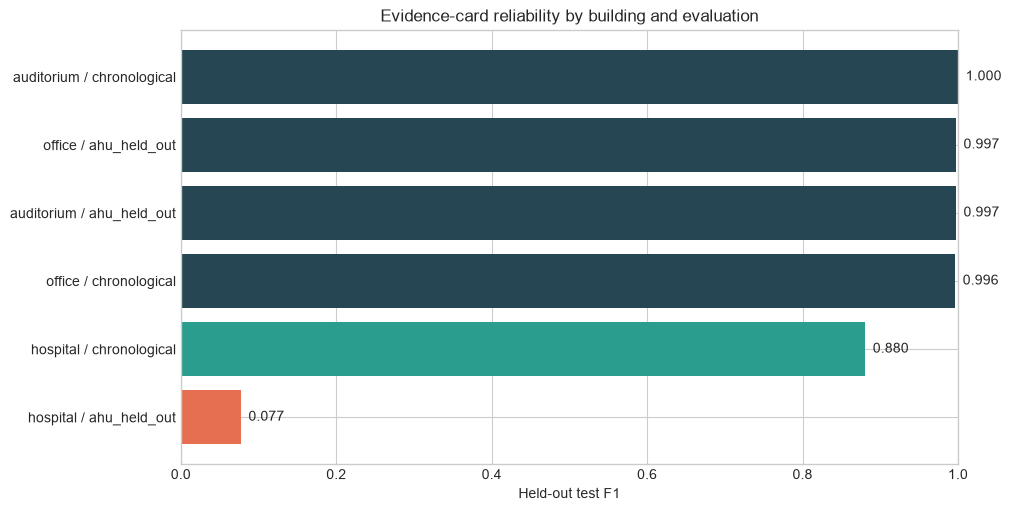

In [4]:
plot_cards = cards.sort_values('f1')
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
bar_colors = [COLORS['fault'] if value < 0.70 else (COLORS['accent'] if value < 0.90 else COLORS['dark']) for value in plot_cards['f1']]
ax.barh(plot_cards['evaluation'], plot_cards['f1'], color=bar_colors)
ax.set_xlim(0, 1)
ax.set_xlabel('Held-out test F1')
ax.set_title('Evidence-card reliability by building and evaluation')
for index, value in enumerate(plot_cards['f1']):
    ax.text(value + 0.01, index, f'{value:.3f}', va='center')
plt.show()

**Recommended staff wording:**

            - `Status: Evaluation evidence` — this is a historical test result, not a live alert.
            - `Building: ...` and `Evaluation: ...` — identify the operating context.
            - `Detection method: ...` — identify the selected model.
            - `Evidence: F1, balanced accuracy, false-positive rate and coverage` — show the supporting numbers.
            - `Operational qualification: ...` — state whether local calibration and human review are required.

## 3. Pooled quality-controlled evidence

In [5]:
pooled_xgb = quality_summary[quality_summary['model'].eq('xgboost')].copy()
display(pooled_xgb[['duplicate_policy', 'design', 'mean_f1', 'mean_balanced_accuracy', 'mean_false_positive_rate', 'mean_coverage']].round(3))

,duplicate_policy,design,mean_f1,mean_balanced_accuracy,mean_false_positive_rate,mean_coverage
3,exclude_ambiguous_keys,ahu_held_out,0.971,0.972,0.002,1.0
7,exclude_ambiguous_keys,building_held_out,0.284,0.584,0.118,1.0
11,exclude_ambiguous_keys,chronological,0.823,0.909,0.176,1.0
15,exclude_ambiguous_keys,nested_grouped,0.956,0.965,0.006,1.0


The pooled result is useful for comparison across buildings, but it should not be presented as proof that a single model is equally reliable everywhere. The building-specific cards show why local validation is important: hospital AHU-held-out performance is materially weaker than auditorium and office.

## 4. What is and is not delivered

In [6]:
deliverables = pd.DataFrame([
    ['Delivered', 'Reproducible Python audit, cleaning, feature, split and modelling pipeline'],
    ['Delivered', 'Saved pooled and building-specific evaluation metrics'],
    ['Delivered', 'Notebook-based visual evidence and interpretation cards'],
    ['Not delivered', 'A live dashboard or live BMS alerting integration'],
    ['Not delivered', 'A calibrated maintenance decision system'],
    ['Required before deployment', 'Target-building calibration, stakeholder review, alert thresholds and monitoring'],
], columns=['status', 'item'])
display(deliverables)

,status,item
0,Delivered,"Reproducible Python audit, cleaning, feature, ..."
1,Delivered,Saved pooled and building-specific evaluation ...
2,Delivered,Notebook-based visual evidence and interpretat...
3,Not delivered,A live dashboard or live BMS alerting integration
4,Not delivered,A calibrated maintenance decision system
5,Required before deployment,"Target-building calibration, stakeholder revie..."


This presentation format is deliberately conservative: it makes the evidence easy to read without hiding the generalisation limits. A facilities team could use the same structure for future live alerts, but the historical dataset alone does not justify calling these cards production alerts.